## Indicaciones sobre la Tarea Académica

> Investigaciones donde eligen su propio camino a partir de una pregunta general, documentando el proceso en un notebook interactivo.
Los asistentes de IA son herramientas de apoyo; el pensamiento crítico y la justificación de decisiones son indispensables.
La responsabilidad final de lo que presenten es suya; no poder explicar un trabajo o atribuido a la IA invalidará la tarea.


## Preguntas Guía para la Investigación

¿Cómo podemos interpretar el espacio latente de un autoencoder desde una perspectiva bayesiana vs. frecuentista? Explora las diferencias conceptuales y matemáticas.

¿Cómo podríamos modificar la función de pérdida de un autoencoder para incorporar principios bayesianos? Explora autoencoders variacionales y su relación con la inferencia bayesiana.

¿De qué manera podemos cuantificar la incertidumbre en las representaciones del espacio latente? Investiga cómo aplicar principios de estadística bayesiana para lograrlo.

Explora el concepto de "manifold learning" en autoencoders y cómo se relaciona con PCA. ¿Cuáles son las implicaciones teóricas y prácticas de estas diferencias?

Investiga cómo el espacio latente de un autoencoder puede ser regularizado para reflejar propiedades específicas de un dominio (física, química, biología), manteniendo la capacidad de reconstrucción.

# Data y definición del Modelo

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np

# 1. Load the MNIST dataset
transform = transforms.Compose([
    transforms.ToTensor()
])

#train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
#test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

train_dataset = datasets.FashionMNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.FashionMNIST(root='./data', train=False, download=True, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=256, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False)

# 2. Define the Autoencoder
class Autoencoder(nn.Module):
    def __init__(self, latent_dim):
        super(Autoencoder, self).__init__()
        self.encoder = nn.Sequential(
            nn.Linear(28 * 28, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, latent_dim),
            nn.ReLU()
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 128),
            nn.ReLU(),
            nn.Linear(128, 28 * 28),
            nn.Sigmoid()  # Output normalized to [0, 1]
        )

    def forward(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded


100%|██████████| 26.4M/26.4M [00:00<00:00, 115MB/s]


Extracting ./data/FashionMNIST/raw/train-images-idx3-ubyte.gz to ./data/FashionMNIST/raw



100%|██████████| 29.5k/29.5k [00:00<00:00, 88.3MB/s]

Extracting ./data/FashionMNIST/raw/train-labels-idx1-ubyte.gz to ./data/FashionMNIST/raw




100%|██████████| 4.42M/4.42M [00:00<00:00, 60.8MB/s]


Extracting ./data/FashionMNIST/raw/t10k-images-idx3-ubyte.gz to ./data/FashionMNIST/raw



100%|██████████| 5.15k/5.15k [00:00<00:00, 18.7MB/s]


Extracting ./data/FashionMNIST/raw/t10k-labels-idx1-ubyte.gz to ./data/FashionMNIST/raw



# Entrenamiento

In [ ]:

latent_dim = 32  # Dimensionality of the latent space
autoencoder = Autoencoder(latent_dim)

# 3. Define Loss Function and Optimizer
criterion = nn.MSELoss()  # Mean squared error loss
optimizer = optim.Adam(autoencoder.parameters(), lr=0.001)

# 4. Training the Autoencoder
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
autoencoder.to(device)

epochs = 10
for epoch in range(epochs):
    autoencoder.train()
    running_loss = 0.0
    for images, _ in train_loader:
        # Flatten images
        images = images.view(images.size(0), -1).to(device)

        # Forward pass
        outputs = autoencoder(images)
        loss = criterion(outputs, images)

        # Backward pass
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    print(f"Epoch [{epoch+1}/{epochs}], Loss: {running_loss/len(train_loader):.4f}")


Epoch [1/10], Loss: 0.0753
Epoch [2/10], Loss: 0.0608
Epoch [3/10], Loss: 0.0570
Epoch [4/10], Loss: 0.0514
Epoch [5/10], Loss: 0.0496
Epoch [6/10], Loss: 0.0488
Epoch [7/10], Loss: 0.0484
Epoch [8/10], Loss: 0.0476
Epoch [9/10], Loss: 0.0472
Epoch [10/10], Loss: 0.0468


# Revisar resultados con el test

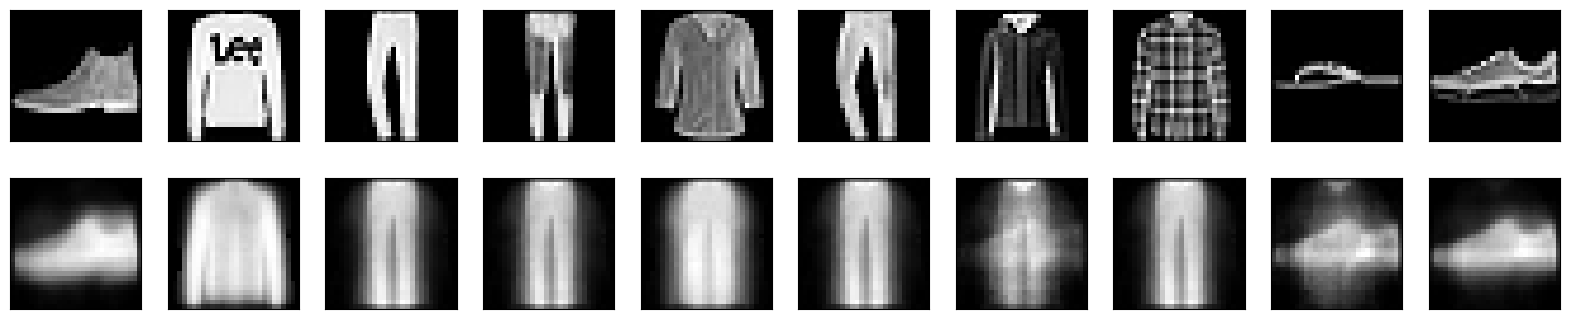

In [ ]:
# 5. Visualize Reconstructed Images
autoencoder.eval()
test_images, _ = next(iter(test_loader))
test_images = test_images.view(test_images.size(0), -1).to(device)
with torch.no_grad():
    reconstructed = autoencoder(test_images)

# Convert back to 28x28 for visualization
test_images = test_images.view(-1, 28, 28).cpu()
reconstructed = reconstructed.view(-1, 28, 28).cpu()

# Plot original and reconstructed images
n = 10
plt.figure(figsize=(20, 4))
for i in range(n):
    # Original images
    ax = plt.subplot(2, n, i + 1)
    plt.imshow(test_images[i], cmap='gray')
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)

    # Reconstructed images
    ax = plt.subplot(2, n, i + 1 + n)
    plt.imshow(reconstructed[i], cmap='gray')
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)
plt.show()


# Generar nuevas imagenes desde el espacio latente

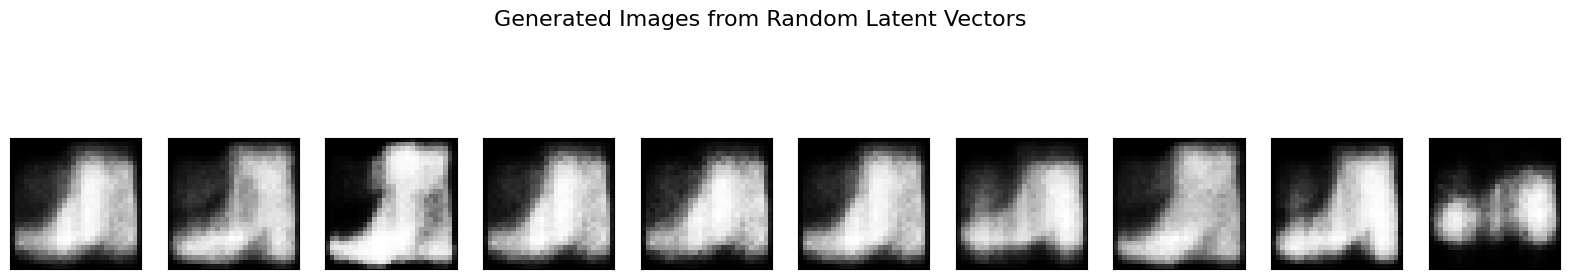

In [ ]:
# 6. Generate New Images
# Generate random latent vectors
random_latent_vectors = torch.randn((10, latent_dim)).to(device)

# Decode random latent vectors
with torch.no_grad():
    generated_images = autoencoder.decoder(random_latent_vectors)

# Convert back to 28x28 for visualization
generated_images = generated_images.view(-1, 28, 28).cpu()

# Plot generated images
plt.figure(figsize=(20, 4))
for i in range(10):
    ax = plt.subplot(1, 10, i + 1)
    plt.imshow(generated_images[i], cmap='gray')
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)
plt.suptitle("Generated Images from Random Latent Vectors", fontsize=16)
plt.show()


In [ ]:
import ipywidgets as widgets
from IPython.display import display, clear_output
import matplotlib.pyplot as plt

# We'll make one slider per latent dimension in the range [-3,3].
sliders = []
for i in range(latent_dim):
    slider = widgets.FloatSlider(
        value=0.0,
        min=-30.0,
        max=30.0,
        step=0.1,
        description=f"z{i}",
        continuous_update=False  # update after releasing the mouse
    )
    sliders.append(slider)

# We'll also have a slider for picking a test image index
test_id_slider = widgets.IntSlider(
    value=0,
    min=0,
    max=len(test_dataset)-1,
    step=1,
    description="Test ID"
)

# Button to set sliders from that test image
set_from_test_button = widgets.Button(
    description="Set from Test Image",
    button_style="primary"
)

# We'll display images in an Output widget
output_widget = widgets.Output()

def update_decoded_image(_):
    """
    Whenever a latent slider changes, decode the new vector & display the image.
    """
    # Collect slider values into a single 1D tensor
    z_tensor = torch.tensor([s.value for s in sliders], device=device, dtype=torch.float32)
    z_tensor = z_tensor.view(1, -1)  # shape (1, latent_dim)

    # Decode
    autoencoder.eval()
    with torch.no_grad():
        generated = autoencoder.decoder(z_tensor)

    generated_img = generated.view(28, 28).cpu().numpy()

    # Display in the output widget
    with output_widget:
        clear_output()
        plt.figure(figsize=(3,3))
        plt.imshow(generated_img, cmap='gray')
        plt.title("Latent -> Decoded Image")
        plt.axis('off')
        plt.show()

def set_sliders_from_test_image(_):
    """
    When the button is clicked, load the test image at test_id_slider, encode it,
    and set each slider to the corresponding latent dimension.
    """
    idx = test_id_slider.value
    # Load test image from dataset
    test_image, _ = test_dataset[idx]  # shape [1,28,28]
    # Flatten & to device
    test_image_flat = test_image.view(1, -1).to(device)

    # Encode
    autoencoder.eval()
    with torch.no_grad():
        encoded = autoencoder.encoder(test_image_flat)  # shape [1, latent_dim]

    encoded_values = encoded[0].cpu().numpy()  # shape [latent_dim]

    # Update each slider
    for i, val in enumerate(encoded_values):
        # If val is out of [-3,3], we clamp it (so the slider won't error).
        val_clamped = float(np.clip(val, -50.0, 50.0))
        sliders[i].value = val_clamped

    # After setting sliders, they'll automatically call update_decoded_image
    # if the slider value changes.

# Attach callbacks
for slider in sliders:
    slider.observe(update_decoded_image, names='value')
set_from_test_button.on_click(set_sliders_from_test_image)

# Display everything
controls_box = widgets.VBox([
    widgets.HBox([test_id_slider, set_from_test_button]),
    widgets.VBox(sliders)
])

ui = widgets.HBox([controls_box, output_widget])
display(ui)

# Initialize the output widget once with the zero latent vector
update_decoded_image(None)
